# 3.1. Practica1. Análisis, implementación y prueba de técnicas de IA a un Dataset de Redes Sociales.

## Introducción de la actividad.

Twitter es una red social que está clasificada como una de las redes más visitados y utilizadas en el mundo con un promedio de más de 58 millones de tweets generados por día. Estos "tweets" son una publicación corta de mensajes (280 caracteres) los cuales se crean y comparten en tiempo real. La velocidad de cómo se puede comunicar esta llegado al punto de que las noticias tradicionales vayan quedando obsoletas, lo que normalmente tomaría 3 horas en ser reportado (noticia), con un tweet compartido en Twitter no tardaría más de 10 minutos en ser conocido entre los usuarios de esta red social.

## Propósito de la actividad

Comprender el funcionamiento de las técnicas de IA aplicadas al BigData (enfoque de Redes Sociales).

## Instrucciones.

Analicé, implemente y evalué técnicas de IA a un dataset de una Red Social acorde a un tema seleccionado, la implementación será en el lenguaje de su preferencia.

## Datos generales

**Alumno:** Marco Sebastián Hernández Parada

**Tema seleccionado:** Análisis de sentimiento de los clientes de aerolíneas de Estados Unidos en Twitter.

**Red social y dataset:** Twitter, *Twitter US Airline Sentiment* (CrowdFlower), publicado en Kaggle: https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Lenguaje y librerías:** Python 3 con pandas, scikit-learn, Matplotlib y Hugging Face Transformers (PyTorch).

**Técnicas de IA aplicadas:**

1. Procesamiento de Lenguaje Natural (PLN) para limpiar y representar el texto (TF-IDF).
2. Aprendizaje supervisado: Naive Bayes, Regresión Logística y Máquina de Vectores de Soporte lineal para clasificar el sentimiento.
3. Aprendizaje profundo: un modelo Transformer (RoBERTa) preentrenado con millones de tweets.
4. Aprendizaje no supervisado: Factorización de Matrices No Negativas (NMF) para descubrir los temas de las quejas.

## 1. Análisis

### 1.1 Planteamiento del problema

Las aerolíneas reciben diariamente miles de menciones en Twitter. Para los clientes es el canal más rápido para quejarse de un vuelo retrasado, una maleta perdida o un mal trato, y cada queja pública puede ser vista por miles de personas en minutos. Un equipo de atención al cliente no puede leer todos los mensajes, por lo que necesita una forma automática de responder dos preguntas:

- **¿Qué opina el cliente?** Clasificar cada tweet como negativo, neutral o positivo para atender primero los negativos.
- **¿De qué se queja?** Agrupar las quejas por tema (retrasos, equipaje, servicio, etc.) para saber qué procesos de la empresa hay que mejorar.

La primera pregunta es un problema de **clasificación supervisada de texto** y la segunda un problema de **descubrimiento de temas no supervisado**. Ambas son tareas típicas de IA aplicada a BigData de redes sociales.

### 1.2 Redes sociales como BigData

Los datos de Twitter cumplen las características que definen al BigData:

| Característica | Cómo se presenta en Twitter |
|---|---|
| Volumen | Millones de tweets por día; solo este dataset reúne 14,640 tweets de una semana para seis aerolíneas. |
| Velocidad | Los mensajes se generan y difunden en tiempo real, por lo que el análisis debe ser automático. |
| Variedad | Texto libre con errores, abreviaturas, emojis, menciones, hashtags y URLs, además de metadatos (fecha, ubicación, usuario). |
| Veracidad | El sentimiento es subjetivo y hay sarcasmo; incluso las etiquetas humanas tienen un nivel de confianza menor a 1. |
| Valor | Detectar a tiempo una crisis de servicio o medir la reputación de la marca frente a la competencia. |

Por la variedad y la falta de estructura del texto, no basta con consultas tradicionales: se necesitan técnicas de PLN y aprendizaje automático que conviertan el texto en información útil.

### 1.3 Análisis de sentimiento

El análisis de sentimiento (*opinion mining*) es el área del PLN que identifica la polaridad de una opinión expresada en un texto (Liu, 2012). Los tweets son un caso difícil porque son cortos, informales y dependen del contexto: "*great, another delay*" contiene la palabra positiva *great* pero es una queja sarcástica.

Existen tres enfoques principales:

- **Basado en léxicos:** cuenta palabras positivas y negativas de un diccionario. No requiere entrenamiento, pero falla con negaciones, sarcasmo y vocabulario de dominio.
- **Aprendizaje automático clásico:** representa el texto como un vector numérico (por ejemplo, TF-IDF) y entrena un clasificador con ejemplos etiquetados.
- **Aprendizaje profundo:** modelos de lenguaje como los Transformers aprenden representaciones contextuales del texto a partir de grandes corpus y luego se especializan en la tarea.

En esta práctica se implementan y comparan los dos últimos.

### 1.4 Técnicas de IA seleccionadas

**Representación TF-IDF.** Cada tweet se convierte en un vector donde cada posición corresponde a un término (palabra o par de palabras). El peso de un término $t$ en el documento $d$ es

$$\text{tfidf}(t, d) = \text{tf}(t, d) \cdot \log\frac{1 + N}{1 + \text{df}(t)} + 1$$

donde $\text{tf}$ es la frecuencia del término en el tweet, $N$ el número de tweets y $\text{df}(t)$ el número de tweets que contienen el término. Así, las palabras que aparecen en casi todos los tweets (como "flight") pesan poco y las que distinguen a unos tweets de otros (como "rude" o "thanks") pesan más (Manning et al., 2008).

**Naive Bayes multinomial.** Clasificador probabilístico que aplica el teorema de Bayes suponiendo que las palabras son independientes dada la clase. Es rápido y sirve como referencia fuerte en clasificación de texto.

**Regresión Logística.** Modelo lineal que estima la probabilidad de cada clase con la función *softmax* sobre una combinación lineal de los pesos TF-IDF. Sus coeficientes indican qué palabras empujan hacia cada sentimiento, por lo que es interpretable.

**Máquina de Vectores de Soporte lineal (SVM).** Busca el hiperplano que separa las clases con el mayor margen posible. Funciona muy bien en espacios de muy alta dimensión y dispersos, como los de TF-IDF.

**Transformer RoBERTa preentrenado en Twitter.** Se utiliza el modelo `cardiffnlp/twitter-roberta-base-sentiment-latest` (Loureiro et al., 2022), una red de 125 millones de parámetros preentrenada con unos 124 millones de tweets y ajustada para sentimiento en el *benchmark* TweetEval (Barbieri et al., 2020). Su mecanismo de atención permite interpretar cada palabra según su contexto, lo que le ayuda con negaciones y sarcasmo. Se aplica **sin reentrenar** con nuestros datos (transferencia directa), para comparar un modelo general con los modelos entrenados específicamente para las aerolíneas.

**Factorización de Matrices No Negativas (NMF).** Técnica no supervisada que descompone la matriz TF-IDF $X$ (tweets por términos) en el producto de dos matrices no negativas, $X \approx WH$ (Lee y Seung, 1999). Cada fila de $H$ es un **tema** descrito por sus palabras de mayor peso y cada fila de $W$ indica cuánto pertenece un tweet a cada tema. Se usa para descubrir de qué se quejan los clientes sin usar etiquetas.

### 1.5 Métricas de evaluación

Las clases están desbalanceadas (la mayoría de los tweets son negativos), así que la exactitud por sí sola es engañosa: un modelo que siempre responde "negativo" obtiene más del 60 % de aciertos. Por eso se reportan:

- **Precisión** de una clase: de los tweets que el modelo asignó a la clase, qué proporción realmente pertenece a ella.
- **Exhaustividad (recall)**: de los tweets que pertenecen a la clase, qué proporción encontró el modelo.
- **F1**: media armónica de precisión y exhaustividad, $F_1 = \frac{2PR}{P + R}$.
- **F1 macro**: promedio simple del F1 de las tres clases, de modo que las clases minoritarias pesan lo mismo que la mayoritaria. Es la **métrica principal** para elegir el modelo.
- **Matriz de confusión**: muestra qué clases se confunden entre sí.

### 1.6 Metodología

1. Cargar el dataset y hacer un análisis exploratorio.
2. Preprocesar el texto de los tweets.
3. Dividir los datos en entrenamiento (80 %) y prueba (20 %) de forma estratificada.
4. Entrenar los modelos clásicos, compararlos con validación cruzada y ajustar los hiperparámetros del mejor.
5. Evaluar en el conjunto de prueba el modelo clásico y el Transformer.
6. Descubrir los temas de las quejas con NMF y compararlos con las razones etiquetadas por personas.
7. Probar los modelos con tweets nuevos.

## 2. Implementación

### 2.1 Librerías y configuración

Se usan pandas para manipular los datos, scikit-learn (Pedregosa et al., 2011) para el preprocesamiento, los modelos clásicos y las métricas, Transformers (Wolf et al., 2020) con PyTorch para el modelo de aprendizaje profundo y Matplotlib (Hunter, 2007) para las gráficas. Los colores de las gráficas siguen el sentimiento: rojo para negativo, gris para neutral y azul para positivo.

In [23]:
import random
import re
import sys
import time
import html
from pathlib import Path
from importlib.metadata import version

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.decomposition import NMF
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

# Semilla para que los resultados sean reproducibles en cada ejecucion
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Carpeta donde se guardan los modelos entrenados
CARPETA_MODELOS = Path("modelos")
CARPETA_MODELOS.mkdir(exist_ok=True)

CLASES = ["negative", "neutral", "positive"]
NOMBRES = {"negative": "Negativo", "neutral": "Neutral", "positive": "Positivo"}
# Paleta divergente: rojo (negativo), gris (neutral), azul (positivo)
COLOR = {"negative": "#e34948", "neutral": "#898781", "positive": "#2a78d6"}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.color": "#0b0b0b",
    "font.size": 9,
})
pd.set_option("display.max_colwidth", 120)

# Versiones usadas, para poder reproducir el entorno
print("Python:", sys.version.split()[0])
for libreria in ["numpy", "pandas", "matplotlib", "scikit-learn", "joblib", "kagglehub",
                 "torch", "transformers", "huggingface_hub"]:
    print(f"{libreria}: {version(libreria)}")

Python: 3.13.7
numpy: 2.3.3
pandas: 2.3.3
matplotlib: 3.10.7
scikit-learn: 1.7.2
joblib: 1.5.2
kagglehub: 1.0.2
torch: 2.11.0+cu128
transformers: 5.18.0
huggingface_hub: 1.33.0


### 2.2 Carga del dataset

El dataset fue creado por CrowdFlower: se recolectaron tweets de febrero de 2015 que mencionaban a seis aerolíneas de Estados Unidos y varias personas etiquetaron su sentimiento y, en los negativos, la razón de la queja. Se lee la copia local `datos/Tweets.csv` si existe; si no, se descarga de Kaggle con `kagglehub`, que la guarda en su caché y la reutiliza en las siguientes ejecuciones.

In [2]:
ARCHIVO_LOCAL = Path("datos/Tweets.csv")
if ARCHIVO_LOCAL.exists():
    archivo = ARCHIVO_LOCAL
else:
    archivo = Path(kagglehub.dataset_download("crowdflower/twitter-airline-sentiment")) / "Tweets.csv"
df_original = pd.read_csv(archivo)

print("Archivo:", archivo)

print("Tweets:", df_original.shape[0], " Columnas:", df_original.shape[1])
df_original[["airline", "airline_sentiment", "negativereason", "text"]].head()

Archivo: datos\Tweets.csv
Tweets: 14640  Columnas: 15


,airline,airline_sentiment,negativereason,text
0,Virgin America,neutral,NaN,@VirginAmerica What @dhepburn said.
1,Virgin America,positive,NaN,@VirginAmerica plus you've added commercials to the experience... tacky.
2,Virgin America,neutral,NaN,@VirginAmerica I didn't today... Must mean I need to take another trip!
3,Virgin America,negative,Bad Flight,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have littl..."
4,Virgin America,negative,Can't Tell,@VirginAmerica and it's a really big bad thing about it


**Columnas utilizadas**

| Columna | Descripción |
|---|---|
| `text` | Texto del tweet (variable de entrada). |
| `airline_sentiment` | Sentimiento etiquetado: `negative`, `neutral` o `positive` (variable objetivo). |
| `airline_sentiment_confidence` | Grado de acuerdo entre los etiquetadores (0 a 1). |
| `negativereason` | Razón de la queja en los tweets negativos (se usa solo para validar los temas de NMF). |
| `airline` | Aerolínea mencionada. |
| `tweet_created` | Fecha y hora de publicación. |

Las demás columnas (coordenadas, zona horaria, columnas *gold*) están vacías en más del 90 % de los registros o no aportan al problema, por lo que se descartan.

In [3]:
print("Valores nulos por columna (%):")
print((df_original.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

cols = ["tweet_id", "airline", "airline_sentiment", "airline_sentiment_confidence",
        "negativereason", "tweet_created", "text"]
df = df_original[cols].copy()
df["tweet_created"] = pd.to_datetime(df["tweet_created"], utc=True).dt.tz_convert("US/Pacific")

# Revertir el reemplazo automático que hicieron los autores del dataset
df["text"] = (df["text"].str.replace("Cancelled Flight", "cancel", case=False)
                        .str.replace("Late Flight", "late", case=False))

duplicados = df.duplicated("text").sum()
df = df.drop_duplicates("text").reset_index(drop=True)
print(f"\nTweets con texto duplicado eliminados: {duplicados}")
print(f"Tweets finales: {len(df)}")
print(f"Periodo: {df.tweet_created.min():%Y-%m-%d} a {df.tweet_created.max():%Y-%m-%d}")

Valores nulos por columna (%):
negativereason_gold             99.8
airline_sentiment_gold          99.7
tweet_coord                     93.0
negativereason                  37.3
user_timezone                   32.9
tweet_location                  32.3
negativereason_confidence       28.1
airline                          0.0
tweet_id                         0.0
airline_sentiment                0.0
airline_sentiment_confidence     0.0
text                             0.0
retweet_count                    0.0
name                             0.0
tweet_created                    0.0

Tweets con texto duplicado eliminados: 213
Tweets finales: 14427
Periodo: 2015-02-16 a 2015-02-24


**Corrección de un error en el texto.** Al revisar las palabras más frecuentes aparecen términos inexistentes como *Flightled*, *Flighted* o *Flightr*. Su origen es que, al preparar el dataset, se reemplazó automáticamente toda aparición de "cancel" por "Cancelled Flight" y de "late" por "Late Flight", incluso dentro de otras palabras. Así, "cancelled" quedó como "Cancelled Flightled" y "later" como "Late Flightr" (alrededor de 1,500 tweets afectados). Se revierte el reemplazo para recuperar el texto original. Es un ejemplo del problema de **veracidad** del BigData: los datos pueden traer errores introducidos durante su recolección que hay que detectar antes de modelar.

Se eliminan los tweets con texto repetido (principalmente retweets y mensajes automáticos) para que un mismo texto no quede a la vez en entrenamiento y prueba, lo que inflaría artificialmente los resultados.

## 3. Análisis exploratorio de los datos

### 3.1 Distribución del sentimiento y por aerolínea

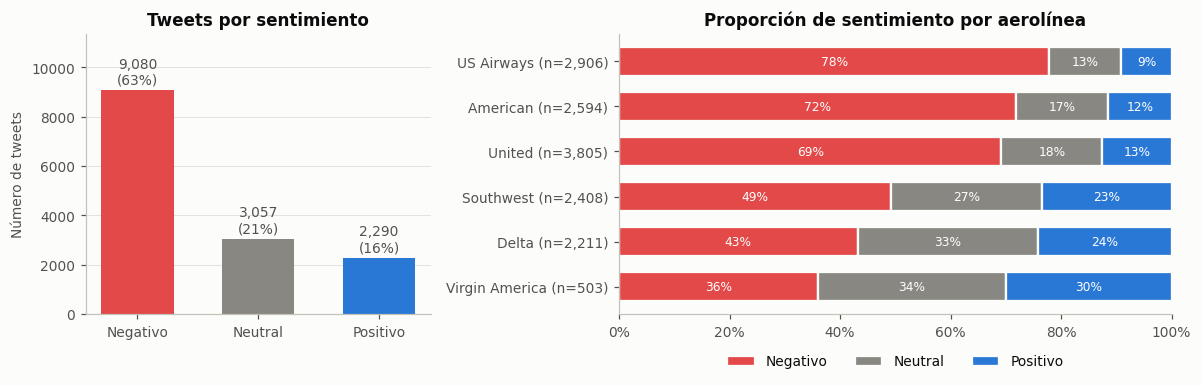

In [4]:
conteo = df["airline_sentiment"].value_counts().reindex(CLASES)
prop = pd.crosstab(df["airline"], df["airline_sentiment"], normalize="index")[CLASES]
prop = prop.sort_values("negative")
n_aerolinea = df["airline"].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})

ax1.bar([NOMBRES[c] for c in CLASES], conteo.values, color=[COLOR[c] for c in CLASES], width=0.6)
for i, v in enumerate(conteo.values):
    ax1.text(i, v + 120, f"{v:,}\n({v / conteo.sum():.0%})", ha="center", va="bottom", color="#52514e")
ax1.set_ylim(0, conteo.max() * 1.25)
ax1.set_title("Tweets por sentimiento")
ax1.set_ylabel("Número de tweets")
ax1.grid(axis="x", visible=False)

izq = np.zeros(len(prop))
etiquetas = [f"{a} (n={n_aerolinea[a]:,})" for a in prop.index]
for c in CLASES:
    ax2.barh(etiquetas, prop[c], left=izq, color=COLOR[c], label=NOMBRES[c],
             height=0.65, edgecolor="#fcfcfb", linewidth=1.5)
    for y, (l, v) in enumerate(zip(izq, prop[c])):
        if v > 0.08:
            ax2.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", color="white", fontsize=8)
    izq += prop[c].values
ax2.set_xlim(0, 1)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax2.set_title("Proporción de sentimiento por aerolínea")
ax2.grid(False)
ax2.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
plt.show()

**Figura 1.** Distribución de los tweets por sentimiento (izquierda) y proporción de cada sentimiento por aerolínea, ordenadas de menor a mayor proporción de tweets negativos (derecha).

- Casi dos de cada tres tweets son negativos: los clientes usan Twitter principalmente para quejarse. El desbalance de clases obliga a usar el F1 macro como métrica y a compensar el peso de las clases en el entrenamiento.
- US Airways, American y United concentran la mayor proporción de quejas, mientras que Virgin America, Delta y Southwest tienen un perfil más equilibrado.

### 3.2 Razones de las quejas

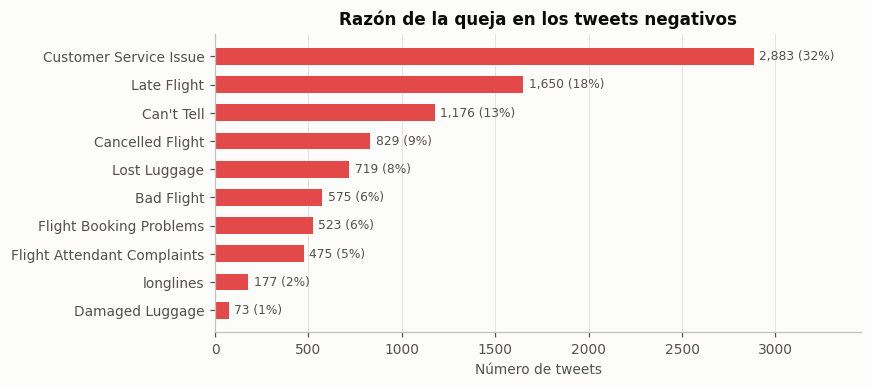

In [5]:
razones = df["negativereason"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(razones.index, razones.values, color=COLOR["negative"], height=0.6)
for y, v in enumerate(razones.values):
    ax.text(v + 30, y, f"{v:,} ({v / razones.sum():.0%})", va="center", color="#52514e", fontsize=8)
ax.set_xlim(0, razones.max() * 1.2)
ax.set_title("Razón de la queja en los tweets negativos")
ax.set_xlabel("Número de tweets")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Figura 2.** Razones de las quejas asignadas por los etiquetadores en los tweets negativos.

El servicio al cliente es la principal causa de quejas, seguido de los vuelos retrasados y cancelados. Esto sugiere que la mayoría de los problemas se relacionan con la operación y la atención, más que con el vuelo en sí.

### 3.3 Longitud de los tweets y confianza de las etiquetas

In [6]:
df["palabras"] = df["text"].str.split().str.len()

resumen = df.groupby("airline_sentiment").agg(
    tweets=("text", "size"),
    palabras_promedio=("palabras", "mean"),
    confianza_promedio=("airline_sentiment_confidence", "mean"),
    confianza_menor_07=("airline_sentiment_confidence", lambda s: (s < 0.7).mean()),
).reindex(CLASES).round(3)
resumen

,tweets,palabras_promedio,confianza_promedio,confianza_menor_07
airline_sentiment,,,,
negative,9080,19.545,0.933,0.178
neutral,3057,14.400,0.823,0.474
positive,2290,14.240,0.872,0.329


Los tweets negativos son más largos: quien se queja explica lo que le pasó, mientras que un agradecimiento suele ser breve. La confianza promedio de las etiquetas neutrales y positivas es menor y una parte de esos tweets tuvo poco acuerdo entre los etiquetadores, lo que anticipa que esas clases serán las más difíciles de distinguir, incluso para una persona.

### 3.4 Ejemplos de tweets

In [7]:
for c in CLASES:
    print(f"--- {NOMBRES[c]} ---")
    for t in df[df.airline_sentiment == c].sample(3, random_state=SEMILLA)["text"]:
        print(" *", t)
    print()

--- Negativo ---
 * @united why do you hire POS pilots? Thanks for ruining my trip and not allowing me to see my buddy as he turns 30. #unitedsucksdick
 * @USAirways thank you for blowing my vacation. Couldn't get me anywhere today to make my reservation and also lost 2 bags of mine!
 * @united Stopped flying @united 1 yr ago bc of aggressive policy on carryon @bdl listening to pssngrs forced to chk@preboard,#notcomingback

--- Neutral ---
 * @JetBlue such a bummer.  But I understand it's a business deal. Thanks for answering me!  Much less sad now.
 * @united I guess that's too much ask, huh?
 * @SouthwestAir #DestinationDragons Any word on winners of contest? Any chance for tix for the Provo DestinationDragons show? Fingers Crossed!

--- Positivo ---
 * @AmericanAir thanks to Jacqueline in CLT for cleaning up @amexserve and @USAirways mess!!! Awesome service
 * @JetBlue  hahah 😂👌👌👌 love flying jet blue tho!! http://t.co/7VeE44MACM
 * @JetBlue sounds good!!!💙💙💙💙



Se observan los rasgos típicos del lenguaje de redes sociales: menciones (`@united`), URLs, hashtags, entidades HTML (`&amp;`), mayúsculas para enfatizar, contracciones y emojis. El preprocesamiento debe normalizar estos elementos sin perder la información de sentimiento.

## 4. Preprocesamiento del texto

### 4.1 Limpieza

La función `limpiar_tweet` aplica los siguientes pasos:

| Paso | Ejemplo antes | Ejemplo después | Razón |
|---|---|---|---|
| Decodificar entidades HTML | `&amp;` | `&` | Son artefactos del formato web. |
| Convertir a minúsculas | `WORST` | `worst` | `Worst` y `worst` deben ser el mismo término. |
| Reemplazar URLs | `http://t.co/x1` | `url` | El enlace concreto no aporta, pero sí el hecho de compartir uno. |
| Eliminar menciones | `@united` | (vacío) | El nombre de la aerolínea no expresa sentimiento y sesgaría al modelo contra las aerolíneas con más quejas. |
| Conservar la palabra del hashtag | `#fail` | `fail` | El hashtag suele contener la opinión. |
| Expandir negaciones | `can't`, `don't` | `can not`, `do not` | La negación invierte el sentimiento. |
| Quitar otras contracciones | `I'm`, `it's` | `i`, `it` | Los sufijos `'m`, `'s`, `'re` no aportan sentimiento. |
| Convertir emoticonos | `:)`, `:(` | `emopos`, `emoneg` | Son señales de sentimiento muy claras. |
| Quitar números y signos | `2 hrs!!!` | `hrs` | Reduce el ruido del vocabulario. |

Las *stopwords* (palabras vacías como *the*, *is*, *a*) se eliminan después, en el vectorizador, **excepto las negaciones** (*not*, *no*, *never*, etc.), porque "*not happy*" y "*happy*" tienen sentimientos opuestos.

In [8]:
NEGACIONES = {"no", "not", "nor", "never", "none", "nothing", "nobody", "nowhere", "cannot", "against"}
STOPWORDS = sorted(ENGLISH_STOP_WORDS - NEGACIONES)

EMO_POS = re.compile(r"(:\)|:-\)|:d|;\)|<3|\u2764|[\U0001F600-\U0001F60D\U0001F44D\U0001F64F])")
EMO_NEG = re.compile(r"(:\(|:-\(|:/|[\U0001F620-\U0001F62D\U0001F612\U0001F61E\U0001F44E])")


def limpiar_tweet(texto):
    t = html.unescape(texto).lower()
    t = re.sub(r"https?://\S+|www\.\S+", " url ", t)
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"#(\w+)", r" \1 ", t)
    t = re.sub(r"can't|cannot", "can not", t)
    t = re.sub(r"won't", "will not", t)
    t = re.sub(r"n't\b", " not", t.replace("’", "'"))
    t = re.sub(r"'\w*", " ", t)
    t = EMO_POS.sub(" emopos ", t)
    t = EMO_NEG.sub(" emoneg ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


df["texto_limpio"] = df["text"].apply(limpiar_tweet)

ejemplos = [df.loc[df.text.str.contains(p, regex=False), "text"].iloc[0]
            for p in ["&amp;", "#fail", ":(", "http"]]
for t in ejemplos:
    print("Original:", t)
    print("Limpio:  ", limpiar_tweet(t), "\n")

Original: @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
Limpio:   it really aggressive to blast obnoxious entertainment in your guests faces they have little recourse 

Original: @VirginAmerica What happened 2 ur vegan food options?! At least say on ur site so i know I won't be able 2 eat anything for next 6 hrs #fail
Limpio:   what happened ur vegan food options at least say on ur site so i know i will not be able eat anything for next hrs fail 

Original: @VirginAmerica awaiting my return phone call, just would prefer to use your online self-service option :(
Limpio:   awaiting my return phone call just would prefer to use your online self service option emoneg 

Original: @VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP
Limpio:   really missed a prime opportunity for men without hats parody there url 



### 4.2 Palabras más características de cada sentimiento

Antes de entrenar, se calcula qué términos son más frecuentes en cada clase en comparación con el resto, usando el promedio de los pesos TF-IDF por clase.

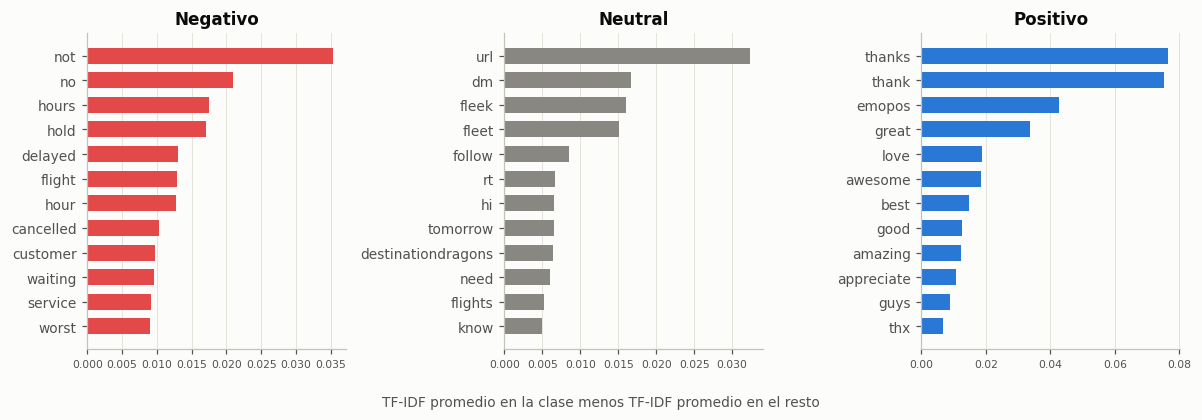

In [9]:
vec_exp = TfidfVectorizer(stop_words=STOPWORDS, min_df=5)
X_exp = vec_exp.fit_transform(df["texto_limpio"])
vocab = np.array(vec_exp.get_feature_names_out())

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, c in zip(axes, CLASES):
    mascara = (df["airline_sentiment"] == c).values
    diferencia = np.asarray(X_exp[mascara].mean(axis=0) - X_exp[~mascara].mean(axis=0)).ravel()
    top = np.argsort(diferencia)[-12:]
    ax.barh(vocab[top], diferencia[top], color=COLOR[c], height=0.65)
    ax.set_title(NOMBRES[c])
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelsize=7)
fig.supxlabel("TF-IDF promedio en la clase menos TF-IDF promedio en el resto", fontsize=9, color="#52514e")
plt.tight_layout()
plt.show()

**Figura 3.** Los doce términos más característicos de cada sentimiento.

Las palabras tienen sentido para cada clase:

- **Negativos:** *not* y *no* encabezan la lista, lo que confirma que conservar las negaciones fue acertado. Les siguen *hours*, *hold*, *delayed*, *cancelled*, *customer*, *service* y *worst*, que coinciden con las razones de la Figura 2.
- **Positivos:** agradecimientos y adjetivos de elogio (*thanks*, *great*, *love*, *awesome*, *amazing*) y el token `emopos` de los emoticonos felices, lo que muestra que convertir los emoticonos aporta información.
- **Neutrales:** tweets que comparten enlaces (*url*), piden un mensaje privado (*dm*), hacen preguntas (*need*, *know*, *tomorrow*) o son retweets (*rt*) de promociones. Llaman la atención *fleek* y *fleet*: provienen de una campaña de JetBlue ("*Our fleet's on fleek*") que muchos usuarios retuitearon con pequeñas variaciones. Es un recordatorio de que en redes sociales unos pocos contenidos virales pueden dominar el vocabulario de una clase.

### 4.3 División en entrenamiento y prueba

Se reserva el 20 % de los tweets para la prueba final. La división es estratificada para conservar la proporción de cada sentimiento en ambos conjuntos. El conjunto de prueba no se usa hasta la evaluación final.

In [10]:
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    df["texto_limpio"], df["airline_sentiment"], df.index,
    test_size=0.2, stratify=df["airline_sentiment"], random_state=SEMILLA)

print(f"Entrenamiento: {len(X_train)} tweets   Prueba: {len(X_test)} tweets")
pd.DataFrame({"Entrenamiento": y_train.value_counts(normalize=True),
              "Prueba": y_test.value_counts(normalize=True)}).reindex(CLASES).round(3)

Entrenamiento: 11541 tweets   Prueba: 2886 tweets


,Entrenamiento,Prueba
airline_sentiment,,
negative,0.629,0.629
neutral,0.212,0.212
positive,0.159,0.159


## 5. Modelos de aprendizaje supervisado

### 5.1 Comparación de modelos con validación cruzada

Cada modelo es un *pipeline* de scikit-learn que une el vectorizador TF-IDF y el clasificador; así el vocabulario y los pesos IDF se calculan solo con los datos de entrenamiento de cada partición y no hay fuga de información. El vectorizador usa palabras individuales y pares de palabras (bigramas), que capturan expresiones como *not happy* o *customer service*.

Se incluye un **modelo base** (`DummyClassifier`) que siempre predice la clase mayoritaria: cualquier modelo útil debe superarlo claramente. La Regresión Logística y la SVM usan `class_weight="balanced"`, que da más peso a los errores en las clases minoritarias.

Los modelos se comparan con validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento.

In [11]:
def tfidf():
    return TfidfVectorizer(stop_words=STOPWORDS, ngram_range=(1, 2), min_df=2, sublinear_tf=True)


modelos = {
    "Base (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes": MultinomialNB(alpha=0.3),
    "Regresión Logística": LogisticRegression(C=3, class_weight="balanced", max_iter=2000, random_state=SEMILLA),
    "SVM lineal": LinearSVC(C=0.3, class_weight="balanced", max_iter=5000, random_state=SEMILLA),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, clf in modelos.items():
    res = cross_validate(Pipeline([("tfidf", tfidf()), ("clf", clf)]), X_train, y_train, cv=cv,
                         scoring=["accuracy", "f1_macro"])
    filas.append({"Modelo": nombre,
                  "Exactitud": res["test_accuracy"].mean(),
                  "F1 macro": res["test_f1_macro"].mean(),
                  "F1 macro (desv. est.)": res["test_f1_macro"].std(),
                  "Tiempo de entrenamiento (s)": res["fit_time"].mean()})

comparacion = pd.DataFrame(filas).set_index("Modelo").round(4)
comparacion

,Exactitud,F1 macro,F1 macro (desv. est.),Tiempo de entrenamiento (s)
Modelo,,,,
Base (clase mayoritaria),0.6294,0.2575,0.0000,0.2010
Naive Bayes,0.7480,0.6202,0.0046,0.1673
Regresión Logística,0.7697,0.7140,0.0106,0.6318
SVM lineal,0.7867,0.7223,0.0070,0.1796


**Lectura de la tabla.** Se comparan cuatro modelos para saber si vale la pena un modelo más complejo:

- **Base (clase mayoritaria):** no aprende nada, siempre responde "negativo". Su exactitud de 0.63 es solo la proporción de tweets negativos, y su F1 macro de 0.26 muestra que no reconoce las otras dos clases. Es el mínimo que cualquier modelo debe superar.
- **Naive Bayes:** mejora mucho la exactitud, pero su F1 macro (0.62) queda por debajo de los modelos lineales porque no compensa el desbalance y tiende a predecir "negativo".
- **Regresión Logística y SVM lineal:** son los mejores (F1 macro de 0.71 y 0.72). La SVM gana por poco y es la que se ajusta en la siguiente sección.

Las columnas son el promedio de las 5 particiones de la validación cruzada. La **desviación estándar** del F1 macro es menor a 0.011 en todos los casos, así que los resultados son estables entre particiones y la diferencia entre modelos no se debe al azar de la división. El **tiempo de entrenamiento** es de fracciones de segundo; la Regresión Logística es la más lenta porque su optimizador necesita más iteraciones para converger.

**Reproducibilidad.** La semilla `SEMILLA = 42` se fija para Python y NumPy al inicio y se pasa como `random_state` a la división de los datos, a las particiones de la validación cruzada, a los modelos y a NMF, de modo que cada ejecución produce los mismos resultados (salvo los tiempos, que dependen de la computadora).

### 5.2 Ajuste de hiperparámetros

Se ajustan los hiperparámetros del modelo con mejor F1 macro mediante búsqueda en malla (`GridSearchCV`) con la misma validación cruzada. Se prueban el tamaño de los n-gramas, la frecuencia mínima de un término y la fuerza de regularización `C` (un valor pequeño produce un modelo más simple y uno grande se ajusta más a los datos).

In [12]:
mejor_nombre = comparacion["F1 macro"].idxmax()
print("Modelo con mejor F1 macro en validación cruzada:", mejor_nombre)

malla = {"tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)], "tfidf__min_df": [1, 2, 3]}
if mejor_nombre == "Naive Bayes":
    malla["clf__alpha"] = [0.1, 0.3, 0.5, 1.0]
else:
    malla["clf__C"] = [0.03, 0.1, 0.3, 1, 3]

busqueda = GridSearchCV(Pipeline([("tfidf", tfidf()), ("clf", modelos[mejor_nombre])]),
                        malla, cv=cv, scoring="f1_macro")
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"F1 macro en validación cruzada: {busqueda.best_score_:.4f}")
modelo_clasico = busqueda.best_estimator_

# Guardar el pipeline completo (vocabulario TF-IDF + pesos del clasificador)
joblib.dump(modelo_clasico, CARPETA_MODELOS / "modelo_clasico.joblib")
print("Modelo guardado en", CARPETA_MODELOS / "modelo_clasico.joblib")

Modelo con mejor F1 macro en validación cruzada: SVM lineal
Mejores hiperparámetros: {'clf__C': 0.1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
F1 macro en validación cruzada: 0.7269
Modelo guardado en modelos\modelo_clasico.joblib


El *pipeline* ganador se guarda con `joblib` en `modelos/modelo_clasico.joblib`. El archivo contiene el vocabulario y los pesos IDF del vectorizador y los coeficientes de la SVM, por lo que puede cargarse con `joblib.load` para clasificar tweets nuevos sin volver a entrenar. Los pesos de RoBERTa no se guardan aquí porque no se modifican: Hugging Face los descarga una sola vez y los conserva en su caché.

## 6. Modelo de aprendizaje profundo: Transformer preentrenado

El modelo `cardiffnlp/twitter-roberta-base-sentiment-latest` se descarga de Hugging Face y se usa con la función `pipeline` de la librería Transformers. A diferencia de los modelos anteriores, recibe el **texto original** (sin limpiar), porque fue preentrenado con tweets reales y su tokenizador maneja mayúsculas, emojis y signos de puntuación, que también expresan sentimiento. Siguiendo el preprocesamiento recomendado por sus autores, solo se reemplazan las menciones por `@user` y los enlaces por `http`.

El modelo no se reentrena con los datos de las aerolíneas: se evalúa directamente sobre el mismo conjunto de prueba. Si hay GPU disponible se utiliza; si no, se ejecuta en CPU (tarda unos minutos).

In [13]:
import torch
from transformers import pipeline, set_seed
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
set_seed(SEMILLA)

dispositivo = 0 if torch.cuda.is_available() else -1
roberta = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                   device=dispositivo, truncation=True)
print("Dispositivo:", "GPU" if dispositivo == 0 else "CPU")


def preparar_roberta(texto):
    t = re.sub(r"@\w+", "@user", texto)
    return re.sub(r"https?://\S+", "http", t)


def predecir_roberta(textos):
    salida = roberta([preparar_roberta(t) for t in textos], batch_size=64)
    return np.array([s["label"] for s in salida])

Dispositivo: GPU


## 7. Evaluación en el conjunto de prueba

### 7.1 Métricas generales

In [14]:
textos_test = df.loc[idx_test, "text"]

inicio = time.perf_counter()
pred_clasico = modelo_clasico.predict(X_test)
t_clasico = time.perf_counter() - inicio

inicio = time.perf_counter()
pred_roberta = predecir_roberta(textos_test.tolist())
t_roberta = time.perf_counter() - inicio

pred_base = np.full(len(y_test), "negative")

resultados = pd.DataFrame({
    "Exactitud": [accuracy_score(y_test, p) for p in (pred_base, pred_clasico, pred_roberta)],
    "F1 macro": [f1_score(y_test, p, average="macro") for p in (pred_base, pred_clasico, pred_roberta)],
    "Tiempo de predicción (s)": [0, t_clasico, t_roberta],
}, index=["Base (clase mayoritaria)", f"{mejor_nombre} + TF-IDF", "RoBERTa (sin reentrenar)"])
resultados["Tweets por segundo"] = (len(y_test) / resultados["Tiempo de predicción (s)"]).replace(np.inf, np.nan)
resultados.round(4)

,Exactitud,F1 macro,Tiempo de predicción (s),Tweets por segundo
Base (clase mayoritaria),0.6292,0.2575,0.0000,NaN
SVM lineal + TF-IDF,0.7931,0.7363,0.0541,53375.7479
RoBERTa (sin reentrenar),0.7654,0.7261,7.2669,397.1458


### 7.2 Reporte por clase

In [15]:
for nombre, pred in [(f"{mejor_nombre} + TF-IDF", pred_clasico), ("RoBERTa (sin reentrenar)", pred_roberta)]:
    print(f"===== {nombre} =====")
    print(classification_report(y_test, pred, labels=CLASES, target_names=[NOMBRES[c] for c in CLASES],
                                digits=3))

===== SVM lineal + TF-IDF =====
              precision    recall  f1-score   support

    Negativo      0.860     0.878     0.869      1816
     Neutral      0.619     0.572     0.595       612
    Positivo      0.737     0.753     0.745       458

    accuracy                          0.793      2886
   macro avg      0.739     0.734     0.736      2886
weighted avg      0.790     0.793     0.791      2886

===== RoBERTa (sin reentrenar) =====
              precision    recall  f1-score   support

    Negativo      0.948     0.771     0.851      1816
     Neutral      0.507     0.644     0.567       612
    Positivo      0.656     0.904     0.760       458

    accuracy                          0.765      2886
   macro avg      0.704     0.773     0.726      2886
weighted avg      0.808     0.765     0.776      2886



### 7.3 Matrices de confusión

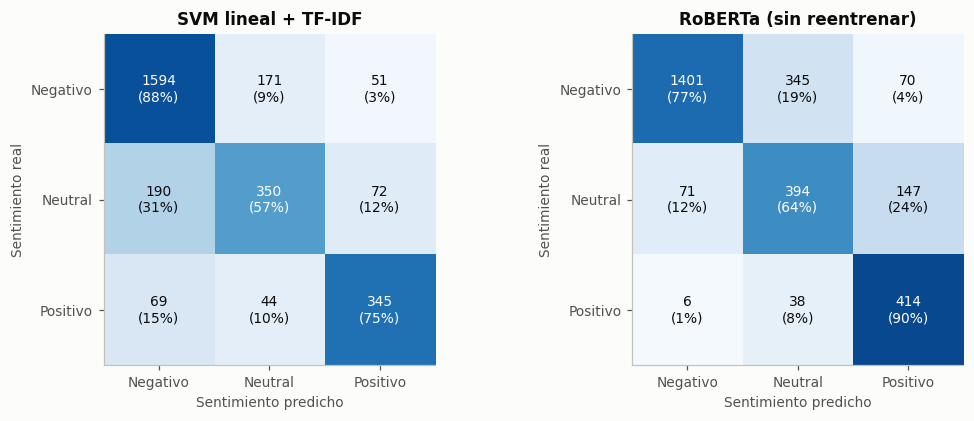

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, (nombre, pred) in zip(axes, [(f"{mejor_nombre} + TF-IDF", pred_clasico),
                                      ("RoBERTa (sin reentrenar)", pred_roberta)]):
    cm = confusion_matrix(y_test, pred, labels=CLASES)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]:.0%})", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.55 else "#0b0b0b", fontsize=9)
    ax.set_xticks(range(3), [NOMBRES[c] for c in CLASES])
    ax.set_yticks(range(3), [NOMBRES[c] for c in CLASES])
    ax.set_xlabel("Sentimiento predicho")
    ax.set_ylabel("Sentimiento real")
    ax.set_title(nombre)
    ax.grid(False)
plt.tight_layout()
plt.show()

**Figura 4.** Matrices de confusión en el conjunto de prueba. Cada celda indica el número de tweets y, entre paréntesis, el porcentaje respecto al total de su clase real (la diagonal es la exhaustividad de cada clase).

### 7.4 Interpretación del modelo clásico

Los modelos lineales permiten ver qué términos pesan más en cada decisión. Los coeficientes positivos de una clase indican términos que hacen más probable esa clase.

In [17]:
vec = modelo_clasico.named_steps["tfidf"]
clf = modelo_clasico.named_steps["clf"]
terminos = np.array(vec.get_feature_names_out())

if hasattr(clf, "coef_"):
    pesos = clf.coef_
else:
    pesos = clf.feature_log_prob_ - clf.feature_log_prob_.mean(axis=0)

tabla = {}
for k, c in enumerate(clf.classes_):
    orden = np.argsort(pesos[k])[::-1][:15]
    tabla[NOMBRES[c]] = [f"{terminos[i]} ({pesos[k, i]:.2f})" for i in orden]
pd.DataFrame(tabla, index=range(1, 16))

,Negativo,Neutral,Positivo
1,not (2.20),hi (1.14),thanks (2.55)
2,no (1.65),question (0.92),thank (2.50)
3,hours (1.64),url (0.87),great (2.31)
4,delayed (1.49),possible (0.87),awesome (2.03)
5,worst (1.47),dm (0.86),amazing (1.77)
6,hold (1.34),chance (0.81),love (1.75)
7,cancelled (1.31),atlanta (0.78),kudos (1.55)
8,hrs (1.28),destinationdragons (0.72),emopos (1.53)
9,nothing (1.28),avgeek (0.72),best (1.44)
10,hour (1.22),know (0.71),thx (1.39)


### 7.5 Análisis de errores

Se revisan algunos tweets en los que el modelo clásico se equivocó con alta seguridad para entender sus limitaciones.

In [18]:
errores = pd.DataFrame({"texto": textos_test.values, "real": y_test.values,
                        "clasico": pred_clasico, "roberta": pred_roberta})
errores = errores[errores.real != errores.clasico]
print(f"Errores del modelo clásico: {len(errores)} de {len(y_test)}")
print(f"De esos errores, RoBERTa acierta en: {(errores.roberta == errores.real).mean():.1%}\n")
errores.sample(8, random_state=7)

Errores del modelo clásico: 597 de 2886
De esos errores, RoBERTa acierta en: 51.9%



,texto,real,clasico,roberta
1883,@SouthwestAir it's ok! Southwest is still the best airline around! Just hate when baggage room runs out.. My now che...,positive,negative,positive
528,@USAirways Why can't I check in online for a flight tomorrow am?,negative,neutral,neutral
2468,@AmericanAir at LAX &amp; just got off the phone w/reservations. Every flight that'd get me to BOS before 11 am tmrw...,neutral,negative,negative
2349,@usairways Thank you for allowing me to spend more money on vacation by buying things I already bought.,negative,positive,positive
1195,@united do you expect to cancel flights out of @DENAirport tomorrow morning given the storm?,negative,neutral,negative
1639,"@SouthwestAir thank you for canceling my flight, last minute of course, to #GIS2015. I'm now missing one full day of...",negative,positive,negative
253,@united empathizes w/ my disappointment that 1stClass flight w/nonworking entertainmnt is worth $50. #UnFriendlySkie...,negative,neutral,negative
2838,@AmericanAir im tryin to book a flight but cant get ahold of anyone!,negative,neutral,negative


## 8. Descubrimiento de temas en las quejas con NMF

Se aplica NMF a los tweets negativos para descubrir automáticamente de qué se quejan los clientes. Este análisis **no usa** la columna `negativereason`; esa columna solo se usa después para comprobar si los temas encontrados coinciden con las razones que asignaron las personas.

Se eligen 8 temas, un número cercano a las 10 razones etiquetadas, y se eliminan términos que aparecen en casi todas las quejas (como *flight*) porque no ayudan a distinguir temas.

In [19]:
negativos = df[df.airline_sentiment == "negative"].copy()

# Aqui si se eliminan las negaciones: no describen el tema de la queja
vec_nmf = TfidfVectorizer(stop_words=sorted(ENGLISH_STOP_WORDS) + ["url", "flight", "flights", "just", "get", "got"],
                          ngram_range=(1, 2), min_df=5, max_df=0.5)
X_neg = vec_nmf.fit_transform(negativos["texto_limpio"])

K = 8
nmf = NMF(n_components=K, init="nndsvd", random_state=SEMILLA, max_iter=500)
W = nmf.fit_transform(X_neg)
H = nmf.components_
terminos_nmf = np.array(vec_nmf.get_feature_names_out())

temas = pd.DataFrame({
    "Palabras principales": [", ".join(terminos_nmf[np.argsort(H[k])[::-1][:10]]) for k in range(K)],
    "Tweets": np.bincount(W.argmax(axis=1), minlength=K),
}, index=[f"Tema {k + 1}" for k in range(K)])
temas

,Palabras principales,Tweets
Tema 1,"plane, gate, waiting, hour, delay, sitting, agent, late, crew, min",1281
Tema 2,"service, customer, customer service, worst customer, worst, terrible, poor, poor customer, terrible customer, line",739
Tema 3,"hold, hours, hold hours, minutes, hour, hold hour, hours hold, hold minutes, trying, min",766
Tema 4,"help, need, phone, trying, need help, change, does, problems, online, booking problems",1376
Tema 5,"delayed, delayed hours, hours, connection, miss, ua, emoneg, miss connection, pm, missed",566
Tema 6,"bag, did, lost, luggage, bags, check, baggage, checked, emoneg, want",1814
Tema 7,"time, airline, worst, fly, guys, like, worst airline, experience, flying, thanks",1815
Tema 8,"cancelled, tomorrow, today, home, rebooked, refund, weather, rebook, hotel, dfw",723


A partir de sus palabras principales se asigna un nombre a cada tema. Para validar la interpretación, se cruza el tema dominante de cada tweet con la razón etiquetada por las personas.

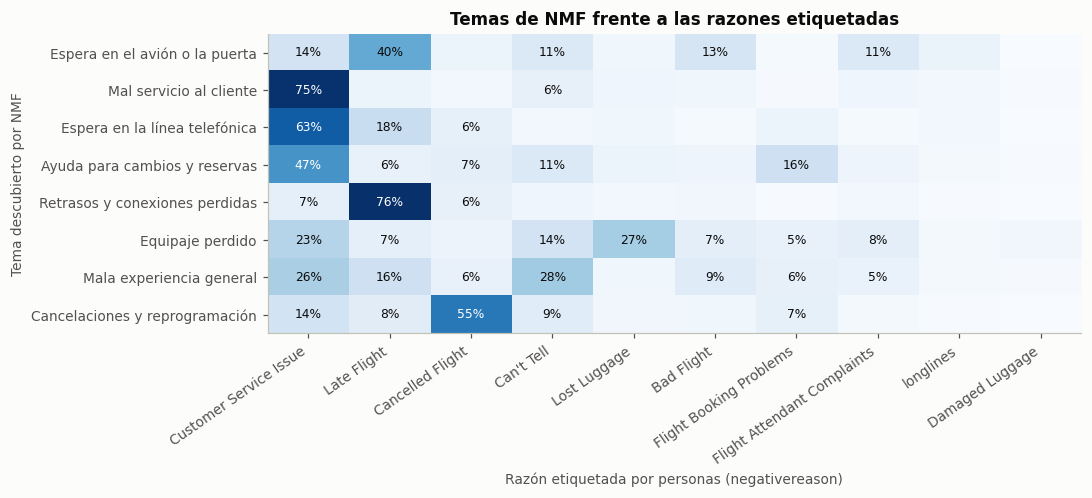

,Nombre asignado,Tweets
Tema 1,Espera en el avión o la puerta,1281
Tema 2,Mal servicio al cliente,739
Tema 3,Espera en la línea telefónica,766
Tema 4,Ayuda para cambios y reservas,1376
Tema 5,Retrasos y conexiones perdidas,566
Tema 6,Equipaje perdido,1814
Tema 7,Mala experiencia general,1815
Tema 8,Cancelaciones y reprogramación,723


In [20]:
NOMBRES_TEMAS = [
    "Espera en el avión o la puerta",
    "Mal servicio al cliente",
    "Espera en la línea telefónica",
    "Ayuda para cambios y reservas",
    "Retrasos y conexiones perdidas",
    "Equipaje perdido",
    "Mala experiencia general",
    "Cancelaciones y reprogramación",
]
temas.insert(0, "Nombre asignado", NOMBRES_TEMAS)

negativos["tema"] = [NOMBRES_TEMAS[k] for k in W.argmax(axis=1)]
cruce = pd.crosstab(negativos["tema"], negativos["negativereason"], normalize="index")
cruce = cruce.loc[NOMBRES_TEMAS, cruce.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.imshow(cruce.values, cmap="Blues", vmin=0, vmax=cruce.values.max(), aspect="auto")
for i in range(cruce.shape[0]):
    for j in range(cruce.shape[1]):
        v = cruce.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.4 else "#0b0b0b")
ax.set_xticks(range(cruce.shape[1]), cruce.columns, rotation=35, ha="right")
ax.set_yticks(range(cruce.shape[0]), cruce.index)
ax.set_xlabel("Razón etiquetada por personas (negativereason)")
ax.set_ylabel("Tema descubierto por NMF")
ax.set_title("Temas de NMF frente a las razones etiquetadas")
ax.grid(False)
plt.tight_layout()
plt.show()

joblib.dump({"vectorizador": vec_nmf, "nmf": nmf, "nombres_temas": NOMBRES_TEMAS},
            CARPETA_MODELOS / "temas_nmf.joblib")

temas[["Nombre asignado", "Tweets"]]

**Figura 5.** Para cada tema descubierto por NMF (filas), distribución de las razones etiquetadas por personas. Una celda oscura indica que la mayoría de los tweets del tema tienen esa razón.

## 9. Prueba con tweets nuevos

Finalmente se prueban los dos modelos con tweets escritos para esta práctica, que no forman parte del dataset. Incluyen casos fáciles, una negación, una pregunta neutral y un caso sarcástico. El modelo clásico se carga desde el archivo guardado en la sección 5.2, como se haría en un sistema en producción.

In [21]:
# Se carga el modelo guardado para comprobar que puede reutilizarse sin reentrenar
modelo_cargado = joblib.load(CARPETA_MODELOS / "modelo_clasico.joblib")

nuevos = [
    "@united thank you so much for the upgrade, the crew was amazing!",
    "@AmericanAir my flight has been delayed 4 hours and nobody tells us anything",
    "@SouthwestAir what time does the gate open for flight 1234 to Denver?",
    "@JetBlue I'm not happy at all, you lost my luggage again",
    "@Delta great, another cancelled flight. Best airline ever...",
    "@VirginAmerica the new app is not bad, booking was quick",
]
pd.DataFrame({
    "Tweet": nuevos,
    f"{mejor_nombre}": [NOMBRES[p] for p in modelo_cargado.predict([limpiar_tweet(t) for t in nuevos])],
    "RoBERTa": [NOMBRES[p] for p in predecir_roberta(nuevos)],
})

,Tweet,SVM lineal,RoBERTa
0,"@united thank you so much for the upgrade, the crew was amazing!",Positivo,Positivo
1,@AmericanAir my flight has been delayed 4 hours and nobody tells us anything,Negativo,Negativo
2,@SouthwestAir what time does the gate open for flight 1234 to Denver?,Negativo,Neutral
3,"@JetBlue I'm not happy at all, you lost my luggage again",Negativo,Negativo
4,"@Delta great, another cancelled flight. Best airline ever...",Positivo,Positivo
5,"@VirginAmerica the new app is not bad, booking was quick",Negativo,Positivo


### 9.1 Aplicación: reputación de cada aerolínea

Como ejemplo de uso para el negocio, se aplica el modelo clásico al conjunto de prueba y se compara la proporción de tweets negativos **predicha** por aerolínea con la proporción **real**. Si el modelo reproduce el orden de las aerolíneas, podría usarse para monitorear la reputación de cada una en tiempo real sin etiquetar tweets manualmente.

In [22]:
monitoreo = pd.DataFrame({"airline": df.loc[idx_test, "airline"].values,
                          "real": (y_test.values == "negative"),
                          "predicho": (pred_clasico == "negative")})
monitoreo = monitoreo.groupby("airline")[["real", "predicho"]].mean().sort_values("real", ascending=False)
monitoreo["diferencia"] = monitoreo["predicho"] - monitoreo["real"]
(monitoreo * 100).round(1).rename(columns={"real": "% negativos real", "predicho": "% negativos predicho",
                                           "diferencia": "Diferencia (puntos)"})

,% negativos real,% negativos predicho,Diferencia (puntos)
airline,,,
US Airways,77.3,75.9,-1.4
American,73.0,71.6,-1.3
United,68.2,71.6,3.4
Southwest,49.2,50.6,1.4
Delta,43.2,46.5,3.3
Virgin America,41.9,46.5,4.7


## 10. Evaluación de resultados

### 10.1 Modelos supervisados

| Modelo | F1 macro (validación cruzada) | Exactitud (prueba) | F1 macro (prueba) |
|---|---|---|---|
| Base (clase mayoritaria) | 0.258 | 0.629 | 0.258 |
| Naive Bayes + TF-IDF | 0.620 | No evaluado | No evaluado |
| Regresión Logística + TF-IDF | 0.714 | No evaluado | No evaluado |
| SVM lineal + TF-IDF (ajustada) | 0.727 | **0.793** | **0.736** |
| RoBERTa preentrenado (sin reentrenar) | No aplica | 0.765 | 0.726 |

Solo el mejor modelo clásico se evalúa en el conjunto de prueba, para no elegir el modelo con los datos que sirven para medirlo. RoBERTa no se entrena, por lo que no tiene validación cruzada.

- **Todos los modelos superan ampliamente al modelo base.** El modelo base tiene 63 % de exactitud solo por el desbalance, pero su F1 macro es de 0.26 porque nunca detecta tweets neutrales ni positivos. Esto confirma que la exactitud no es una métrica adecuada para este problema.
- **La SVM lineal fue el mejor modelo clásico.** Naive Bayes queda claramente atrás porque, sin compensar el desbalance, tiende a asignar casi todo a la clase negativa. La Regresión Logística y la SVM tienen resultados parecidos; la SVM ganó por poco y es más rápida de entrenar.
- **El ajuste de hiperparámetros aportó poco** (de 0.722 a 0.727). La búsqueda eligió una regularización fuerte ($C = 0.1$) y solo palabras individuales: con tan pocos datos, los bigramas agregan muchas columnas raras y el modelo regularizado ya captura la negación mediante el término *not*, que es el de mayor peso negativo.
- **El resultado en prueba (0.736) es consistente con la validación cruzada (0.727)**, de modo que el modelo no está sobreajustado y la estimación de su desempeño es confiable.

### 10.2 Modelo clásico frente al Transformer

La SVM, entrenada específicamente con tweets de aerolíneas, supera ligeramente en F1 macro al Transformer, que nunca vio estos datos. Sin embargo, sus errores son de naturaleza distinta (Figura 4):

- **RoBERTa es más conservador con lo negativo:** cuando dice "negativo" acierta el 95 % de las veces, pero clasifica como neutral el 19 % de las quejas. Muchas quejas de aerolínea están redactadas como preguntas o como hechos ("*why can't I check in online?*", "*my flight is delayed*"), que un modelo general considera neutrales, mientras que en este dominio casi siempre son una queja.
- **RoBERTa reconoce mejor los tweets positivos** (exhaustividad de 90 % contra 75 %) y entiende expresiones que dependen del orden de las palabras: en la prueba con tweets nuevos clasificó bien "*not bad*" y la pregunta sobre la puerta de embarque, que la SVM confundió por contener términos asociados a quejas (*not*, *bad*, *gate*, *time*).
- **Los modelos se complementan:** RoBERTa acierta en el 52 % de los tweets en los que la SVM se equivoca. Ajustar (*fine-tuning*) el Transformer con los tweets de entrenamiento o combinar ambos modelos son mejoras naturales para una siguiente versión.
- **Costo computacional:** la SVM clasifica decenas de miles de tweets por segundo en CPU, mientras que RoBERTa procesa unos cientos por segundo incluso con GPU; es decir, el modelo clásico es más de cien veces más rápido. Para monitorear millones de tweets en tiempo real, el modelo clásico es mucho más barato; el Transformer conviene cuando se requiere mayor comprensión del lenguaje.

**La clase neutral es la más difícil para ambos modelos** (F1 de 0.60 y 0.57). Esto coincide con el análisis exploratorio: el 47 % de los tweets neutrales tuvo poco acuerdo entre los etiquetadores, así que parte del error se debe a la ambigüedad de las propias etiquetas. Ninguno de los modelos detectó el sarcasmo del tweet "*great, another cancelled flight. Best airline ever...*", una limitación conocida del análisis de sentimiento.

### 10.3 Descubrimiento de temas

Sin usar ninguna etiqueta, NMF encontró temas que corresponden a problemas reales de las aerolíneas, y la Figura 5 muestra que la mayoría coincide con las razones asignadas por personas:

- *Retrasos y conexiones perdidas* corresponde en un 76 % a la razón **Late Flight**, *Mal servicio al cliente* en un 75 % a **Customer Service Issue** y *Cancelaciones y reprogramación* en un 55 % a **Cancelled Flight**.
- NMF separó en un tema propio la **espera en la línea telefónica** (*hold*, *hours*, *minutes*), que las etiquetas humanas agrupan dentro de "Customer Service Issue". Es decir, el método no supervisado ofrece un nivel de detalle que la clasificación manual no tenía y que es útil para el negocio: indica que una parte importante de las quejas de servicio se resolvería reforzando el centro de llamadas.
- Los temas *Equipaje perdido* y *Mala experiencia general* se mezclan con varias razones. Un mismo tweet puede quejarse de varias cosas a la vez (por ejemplo, de la maleta perdida y de la mala atención al reclamarla), pero solo tiene una etiqueta, mientras que NMF asigna a cada tweet un grado de pertenencia a todos los temas.

### 10.4 Aplicación al monitoreo de reputación

La proporción de tweets negativos predicha por el modelo difiere de la real entre 1 y 5 puntos porcentuales, y la mayor diferencia corresponde a Virgin America, la aerolínea con menos tweets. El modelo separa correctamente los dos grupos de aerolíneas: US Airways, American y United con más de 70 % de tweets negativos, y Southwest, Delta y Virgin America con alrededor de 50 % o menos. El orden dentro de cada grupo solo falla en Delta y Virgin America, que en la predicción quedan prácticamente empatadas (46.5 %) aunque en realidad las separan 1.3 puntos. Esto muestra que, aunque el modelo se equivoca en tweets individuales, sus errores se compensan en gran medida al agregar miles de tweets, por lo que es adecuado para medir la reputación de una marca y compararla con la competencia de forma automática.

### 10.5 Limitaciones

- El dataset es de 2015, cubre solo una semana y está en inglés; el lenguaje y los temas de queja cambian con el tiempo, por lo que el modelo tendría que reentrenarse periódicamente.
- La representación TF-IDF ignora el orden de las palabras y no comprende el sarcasmo ni el contexto.
- Las etiquetas tienen ruido, sobre todo en la clase neutral, lo que pone un límite al desempeño que puede alcanzar cualquier modelo.
- El número de temas de NMF (8) se eligió con criterio propio; podría ajustarse con métricas de coherencia de temas.

## 11. Conclusiones

La práctica mostró el ciclo completo de aplicación de técnicas de IA a datos de una red social: obtención de los datos, limpieza, análisis exploratorio, representación del texto, entrenamiento, evaluación e interpretación. La etapa de preparación resultó tan importante como el modelo: detectar el error de reemplazo de palabras del dataset, eliminar duplicados y decidir qué conservar del lenguaje de Twitter (negaciones, emoticonos, hashtags) influyó directamente en la calidad de los resultados.

Con aprendizaje supervisado se construyó un clasificador de sentimiento con F1 macro de 0.74 y 79 % de exactitud, muy por encima del modelo base. Un modelo lineal sobre TF-IDF es sencillo, rápido e interpretable, y sus coeficientes revelan qué palabras motivan cada decisión. El Transformer preentrenado obtuvo un resultado similar sin haber visto los datos de las aerolíneas, gracias a lo aprendido de millones de tweets, y comprende mejor expresiones como las negaciones; a cambio, es más de cien veces más lento. La elección entre ambos depende del volumen de datos y de los recursos disponibles, un compromiso central en BigData.

Con aprendizaje no supervisado, NMF descubrió los principales motivos de queja sin necesidad de etiquetas e incluso distinguió un problema (la espera telefónica) que la clasificación manual no separaba. Combinadas, estas técnicas convierten miles de mensajes desestructurados en información para la toma de decisiones: qué clientes atender primero, qué procesos mejorar y cómo evoluciona la reputación de la marca frente a la competencia, que es justamente el valor que la IA aporta al BigData de redes sociales.

## Referencias

- Barbieri, F., Camacho-Collados, J., Espinosa Anke, L. y Neves, L. (2020). TweetEval: Unified benchmark and comparative evaluation for tweet classification. En *Findings of the Association for Computational Linguistics: EMNLP 2020* (pp. 1644-1650). https://doi.org/10.18653/v1/2020.findings-emnlp.148
- CrowdFlower. (2016). *Twitter US Airline Sentiment* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment
- Hernández Parada, M. S. (2026). *Análisis, implementación y prueba de técnicas de IA a un Dataset de Redes Sociales* [Repositorio de GitHub]. GitHub. [Ver en GitHub](https://github.com/RKCbas/LENGUAJES-DE-CIENCIA-DE-DATOS-B-SICO---PRACTICAS/blob/main/Cuatrimestre%204/9%20-%20T%C3%B3picos%20de%20IA%20para%20la%20transformaci%C3%B3n%20digital/Practica%203.1/An%C3%A1lisis%2C%20implementaci%C3%B3n%20y%20prueba%20de%20t%C3%A9cnicas%20de%20IA%20a%20un%20Dataset%20de%20Redes%20Sociales.ipynb)
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55
- Lee, D. D. y Seung, H. S. (1999). Learning the parts of objects by non-negative matrix factorization. *Nature, 401*(6755), 788-791. https://doi.org/10.1038/44565
- Liu, B. (2012). *Sentiment Analysis and Opinion Mining*. Morgan & Claypool. https://doi.org/10.2200/S00416ED1V01Y201204HLT016
- Loureiro, D., Barbieri, F., Neves, L., Espinosa Anke, L. y Camacho-Collados, J. (2022). TimeLMs: Diachronic language models from Twitter. En *Proceedings of the 60th Annual Meeting of the Association for Computational Linguistics: System Demonstrations* (pp. 251-260). https://doi.org/10.18653/v1/2022.acl-demo.25
- Manning, C. D., Raghavan, P. y Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., ... Rush, A. M. (2020). Transformers: State-of-the-art natural language processing. En *Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations* (pp. 38-45). https://doi.org/10.18653/v1/2020.emnlp-demos.6